# 02 · What the 1-second data looks like

Before building a strategy, this notebook measures five properties of the data. Each one decides something about how the strategy is built in notebook 03.

| # | Question | Why it matters for the strategy |
|---|---|---|
| 1 | When is BTC most volatile and most traded? | Time of day becomes a feature; volatility must be scaled for it |
| 2 | Are 1-second returns predictable from their own past? | Shows how much of the "signal" at 1 second is microstructure noise |
| 3 | How does measured volatility change with sampling frequency? | Picks the bar size to model |
| 4 | How fat are the tails? | Decides how robust the loss and the position sizing need to be |
| 5 | Does volatility cluster? Does order-flow imbalance lead returns? | Candidate predictive features |

The 1-second history is about 120 million rows, so it is processed **one month at a time**: each month is reduced to a few small sums (`patterns.month_stats`), and the sums are added up (`patterns.combine`).

In [1]:
SYMBOL, INTERVAL = "BTCUSDT", "1s"
DATA_DIR = None        # None = <repo>/data

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from btc import data, quality, patterns, plotting
plotting.use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA = Path(DATA_DIR) if DATA_DIR else ROOT / "data"
RAW, PQ, PROC = DATA / "raw", DATA / "parquet", DATA / "processed"
for d in (RAW, PQ, PROC): d.mkdir(parents=True, exist_ok=True)

In [3]:
files = data.parquet_files(PQ, SYMBOL, INTERVAL)
stats = [patterns.month_stats(data.clean(pd.read_parquet(f))) for f in files]
S = patterns.combine(stats)
print(f"{len(files)} months, {S['mom']['n']:,} one-second returns")

47 months, 122,156,828 one-second returns


## 1. Time of day and day of week

Crypto trades 24/7, but activity still follows the working day of the people trading it.

**How to read it:** the left chart is annualised volatility computed only from seconds in that UTC hour. The right chart is each hour's share of total volume; if every hour were equal, each bar would be 4.17%.

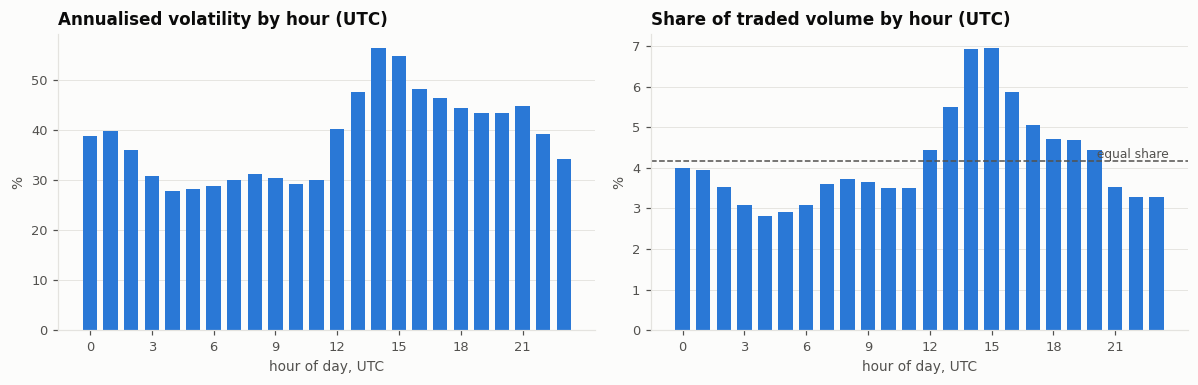

Most volatile hour: 14:00 UTC (56.2%).  Quietest: 04:00 UTC (27.8%).  Ratio 2.02x


In [4]:
h = S["hourly"].groupby("hour").sum()
vol_h = 100 * patterns.ann_vol(h.r2, h.n)
share = 100 * h.volume / h.volume.sum()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.bar(h.index, vol_h, width=0.7, color=plotting.BLUE)
a.set_title("Annualised volatility by hour (UTC)"); a.set_ylabel("%"); a.set_xlabel("hour of day, UTC")
b.bar(h.index, share, width=0.7, color=plotting.BLUE)
b.axhline(100/24, color=plotting.MUTED, lw=1, ls="--"); b.text(23.6, 100/24, " equal share", va="bottom", ha="right", fontsize=8, color=plotting.MUTED)
b.set_title("Share of traded volume by hour (UTC)"); b.set_ylabel("%"); b.set_xlabel("hour of day, UTC")
for ax in (a, b): ax.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()
print(f"Most volatile hour: {vol_h.idxmax():02d}:00 UTC ({vol_h.max():.1f}%).  Quietest: {vol_h.idxmin():02d}:00 UTC ({vol_h.min():.1f}%).  Ratio {vol_h.max()/vol_h.min():.2f}x")

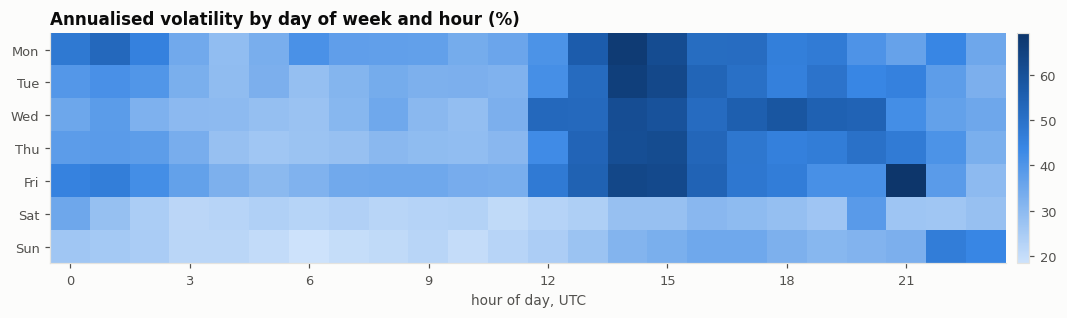

Average weekday volatility 41.8%  vs weekend 27.0%


In [5]:
g = S["hourly"]
grid = (100 * patterns.ann_vol(g.r2, g.n)).unstack("hour")
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(grid.values, aspect="auto", cmap=plotting.SEQ)
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of day, UTC"); ax.grid(False)
ax.set_title("Annualised volatility by day of week and hour (%)")
fig.colorbar(im, ax=ax, pad=0.01); plt.tight_layout(); plt.show()
wk = grid.loc[:4].values.mean(); we = grid.loc[5:].values.mean()
print(f"Average weekday volatility {wk:.1f}%  vs weekend {we:.1f}%")

## 2. Are 1-second returns predictable from their own past?

**Autocorrelation at lag k** is the correlation between the return in one second and the return k seconds earlier. Zero means the past return says nothing about the next one.

At this frequency the usual finding is a **negative** value at lag 1. That is *bid-ask bounce*: trades alternate between the bid and the ask, so the last-trade price flips up and down by one spread even when the true price has not moved. It looks like mean reversion but is not a real price move. This is the main reason notebook 03 does not model 1-second returns directly.

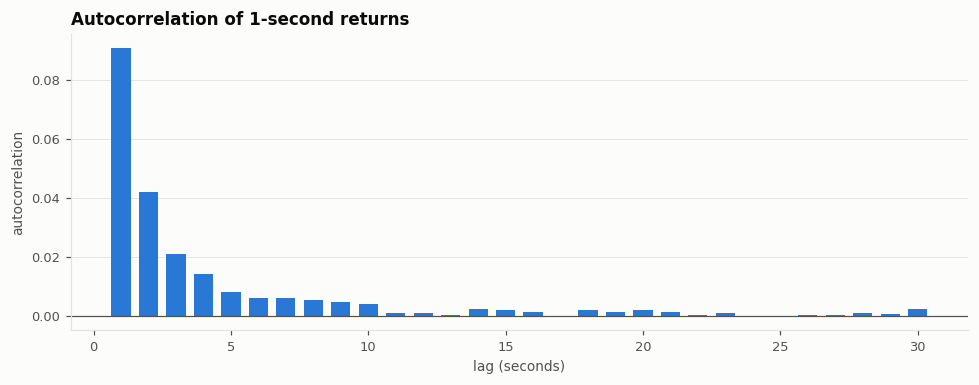

Lags 1-5: +0.0910, +0.0418, +0.0211, +0.0140, +0.0082


In [6]:
ac = S["acf"]
fig, ax = plt.subplots()
ax.bar(ac.index, ac.values, width=0.7, color=plotting.BLUE); ax.axhline(0, color=plotting.MUTED, lw=0.8)
ax.set_title("Autocorrelation of 1-second returns"); ax.set_xlabel("lag (seconds)"); ax.set_ylabel("autocorrelation")
plt.tight_layout(); plt.show()
print("Lags 1-5:", ", ".join(f"{v:+.4f}" for v in ac.head(5)))

## 3. Volatility signature: which bar size is safe to model?

If prices were a pure random walk, annualised volatility would come out the same whether it is measured from 1-second, 1-minute or 1-hour returns. Microstructure noise breaks that: bounce adds variance to every return, and at high frequency there are far more returns, so measured volatility is **inflated at short intervals** and settles down as the interval grows.

**How to read it:** the interval where the line flattens is the shortest bar size at which returns mostly reflect real price moves. That is the bar size used for modelling.

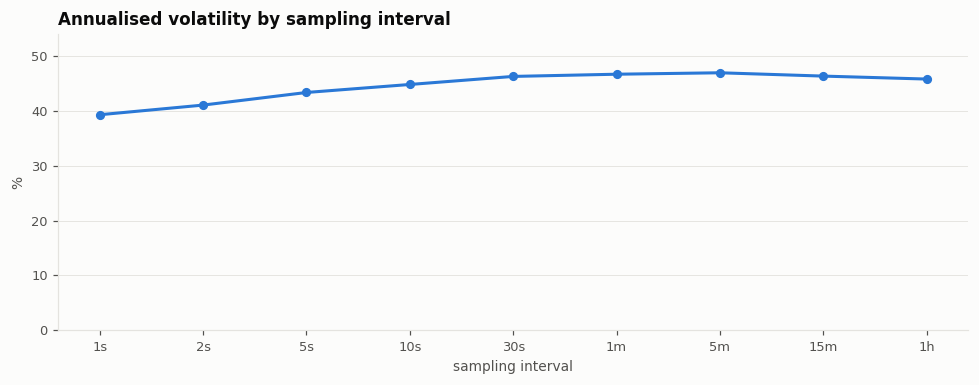

1s: 39.3%   1m: 46.7%   1h: 45.9%   ->  1-second volatility is 0.86x the hourly figure


In [7]:
sig = 100 * S["signature"]
lab = {1: "1s", 2: "2s", 5: "5s", 10: "10s", 30: "30s", 60: "1m", 300: "5m", 900: "15m", 3600: "1h"}
fig, ax = plt.subplots()
ax.plot(range(len(sig)), sig.values, marker="o", color=plotting.BLUE)
ax.set_xticks(range(len(sig))); ax.set_xticklabels([lab[s] for s in sig.index])
ax.set_title("Annualised volatility by sampling interval"); ax.set_xlabel("sampling interval"); ax.set_ylabel("%")
ax.set_ylim(0, sig.max() * 1.15)
plt.tight_layout(); plt.show()
print(f"1s: {sig[1]:.1f}%   1m: {sig[60]:.1f}%   1h: {sig[3600]:.1f}%   ->  1-second volatility is {sig[1]/sig[3600]:.2f}x the hourly figure")

## 4. Fat tails

**Kurtosis** measures how much of the variance comes from extreme moves. A normal distribution has kurtosis 3. Financial returns are far above that, more so at short horizons.

In [8]:
m1 = pd.read_parquet(PROC / f"{SYMBOL}-1m.parquet")
m1 = m1[m1.n_obs >= 50]                      # drop minutes built from too few seconds
consec = m1.index.to_series().diff() == pd.Timedelta(minutes=1)
r1 = np.log(m1.close).diff().where(consec)   # 1-minute return, only across consecutive minutes

mom = S["mom"]; x = r1.dropna().to_numpy()
pd.DataFrame({
    "observations": [mom["n"], x.size],
    "kurtosis (normal = 3)": [patterns.kurtosis(mom["s2"], mom["s4"], mom["n"]), patterns.kurtosis((x**2).sum(), (x**4).sum(), x.size)],
    "% of returns exactly zero": [100 * mom["zero"] / mom["n"], 100 * (x == 0).mean()],
    "largest |return| (%)": [np.nan, 100 * np.abs(x).max()],
}, index=["1-second", "1-minute"]).style.format({"observations": "{:,.0f}", "kurtosis (normal = 3)": "{:,.1f}",
        "% of returns exactly zero": "{:.2f}", "largest |return| (%)": "{:.2f}"}, na_rep="")

,observations,kurtosis (normal = 3),% of returns exactly zero,largest |return| (%)
1-second,"122,156,828",630.1,42.81,
1-minute,"2,036,077",79.0,3.65,4.38


## 5a. Volatility clustering

Returns themselves are close to unpredictable, but their **size** is not: large moves follow large moves. The chart shows the autocorrelation of the absolute 1-minute return, out to two days.

**How to read it:** a line that stays above zero for hundreds of minutes means volatility is persistent and forecastable. Bumps at 1,440 and 2,880 minutes (one and two days) are the time-of-day pattern from section 1 showing up again.

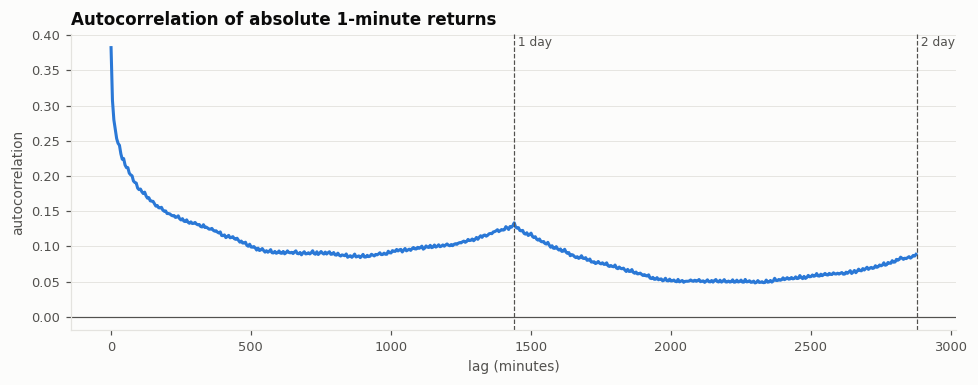

Raw 1-minute return autocorrelation, lags 1-5: -0.0012, -0.0053, -0.0052, -0.0038, -0.0033


In [9]:
lags = np.arange(1, 2881, 5)
a_abs = patterns.acf(np.abs(x), lags)
a_raw = patterns.acf(x, range(1, 11))

fig, ax = plt.subplots()
ax.plot(a_abs.index, a_abs.values, color=plotting.BLUE)
for d in (1440, 2880):
    ax.axvline(d, color=plotting.MUTED, lw=0.8, ls="--"); ax.text(d, ax.get_ylim()[1], f" {d//1440} day", va="top", fontsize=8, color=plotting.MUTED)
ax.axhline(0, color=plotting.MUTED, lw=0.8)
ax.set_title("Autocorrelation of absolute 1-minute returns"); ax.set_xlabel("lag (minutes)"); ax.set_ylabel("autocorrelation")
plt.tight_layout(); plt.show()
print("Raw 1-minute return autocorrelation, lags 1-5:", ", ".join(f"{v:+.4f}" for v in a_raw.head(5)))

## 5b. Order-flow imbalance

The kline data has one column most candidates ignore: `taker_buy_volume`. From it:

**imbalance = (aggressive buying − aggressive selling) / total volume**, between −1 and +1.

Minutes are sorted into ten equal buckets by imbalance. The left chart shows the return in the **same** minute: this should slope up steeply, because aggressive buying is what moves the price. It is not tradeable, since the imbalance is only known once the minute is over. The right chart shows the return in the **next** minute, which is the tradeable question. Error bars are ±2 standard errors.

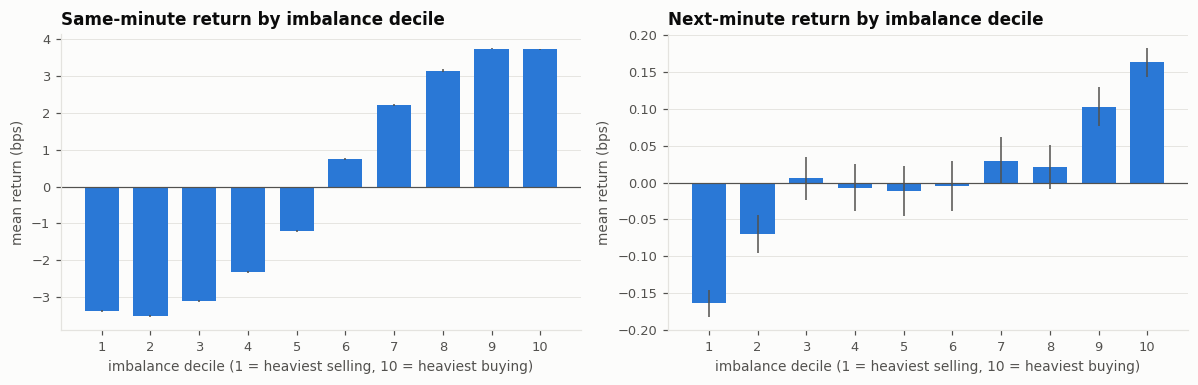

Correlation of imbalance with same-minute return: +0.421,  with next-minute return: +0.0125


In [10]:
imb = (2 * m1.taker_buy_volume / m1.volume - 1).where(m1.volume > 0)
nxt = r1.shift(-1)                            # next minute's return (NaN if the next minute is missing)
same, lead = patterns.decile_table(imb, r1), patterns.decile_table(imb, nxt)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, t, title in zip(axes, (same, lead), ("Same-minute return by imbalance decile", "Next-minute return by imbalance decile")):
    ax.bar(t.index, t.mean_bps, yerr=2 * t.se_bps, width=0.7, color=plotting.BLUE, ecolor=plotting.MUTED, error_kw={"lw": 1})
    ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.set_xticks(t.index)
    ax.set_title(title); ax.set_xlabel("imbalance decile (1 = heaviest selling, 10 = heaviest buying)"); ax.set_ylabel("mean return (bps)")
plt.tight_layout(); plt.show()
print(f"Correlation of imbalance with same-minute return: {imb.corr(r1):+.3f},  with next-minute return: {imb.corr(nxt):+.4f}")

## What this means for notebook 03

1. **Time of day:** volatility in the busiest hour (14:00 UTC, 56%) is **2.0x** the quietest (04:00 UTC, 28%), and weekdays average 42% against 27% at weekends → hour-of-day and weekend features; returns scaled by recent volatility.
2. **1-second autocorrelation:** lag 1 is **+0.091**, and lags 1–5 are all positive and decay. This is the opposite of bid-ask bounce. BTC/USDT trades at about $64,000 with a 1-cent tick, so bounce is negligible. Instead, 43% of seconds show no price change, and moves arrive in bursts spread over several consecutive seconds. Either way, 1-second closes do not reflect real price moves → do not model or trade at 1-second closes.
3. **Signature plot:** volatility is **39%** at 1 s and settles at about **46–47%** from 1 minute on (46.7% at 1 m, 45.9% at 1 h). The 1-second figure is low because moves continue across seconds → model 1-minute bars or longer.
4. **Tails:** 1-minute kurtosis is **79** (630 at 1 second; a normal distribution is 3), and the largest 1-minute move is 4.4% → clip features, and report results with and without the most extreme days.
5. **Clustering:** absolute-return autocorrelation is still **0.22** after one hour and 0.14 after one day → realised-volatility features; volatility is far more forecastable than direction.
6. **Imbalance:** it correlates +0.42 with the same minute's return but only +0.013 with the next. The next-minute difference between deciles 10 and 1 is **0.33 bps**: statistically clear, but small → keep it as one feature among several rather than a strategy on its own.
